In [1]:
import re
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          MarianMTModel, MarianTokenizer)

audio_file = "Kokeilu_2.wav"

# pip install transformers librosa ipywidgets sentencepiece sacremoses

W1112 02:13:50.201000 58092 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
# Load audio file
y, sr = librosa.load(audio_file, sr=16000)

# Display audio for playback
print("Play the audio:")
display(Audio(y, rate=sr))

# Print audio statistics
duration = librosa.get_duration(y=y, sr=sr)
print(f"\nAudio Statistics:")
print(f"Duration: {duration:.2f} seconds")
print(f"Sample rate: {sr} Hz")

Play the audio:



Audio Statistics:
Duration: 38.12 seconds
Sample rate: 16000 Hz


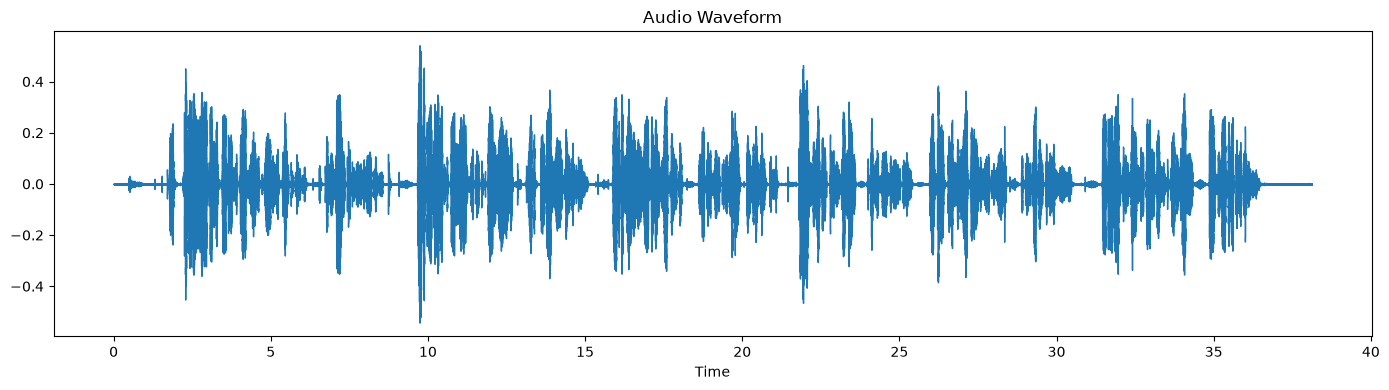

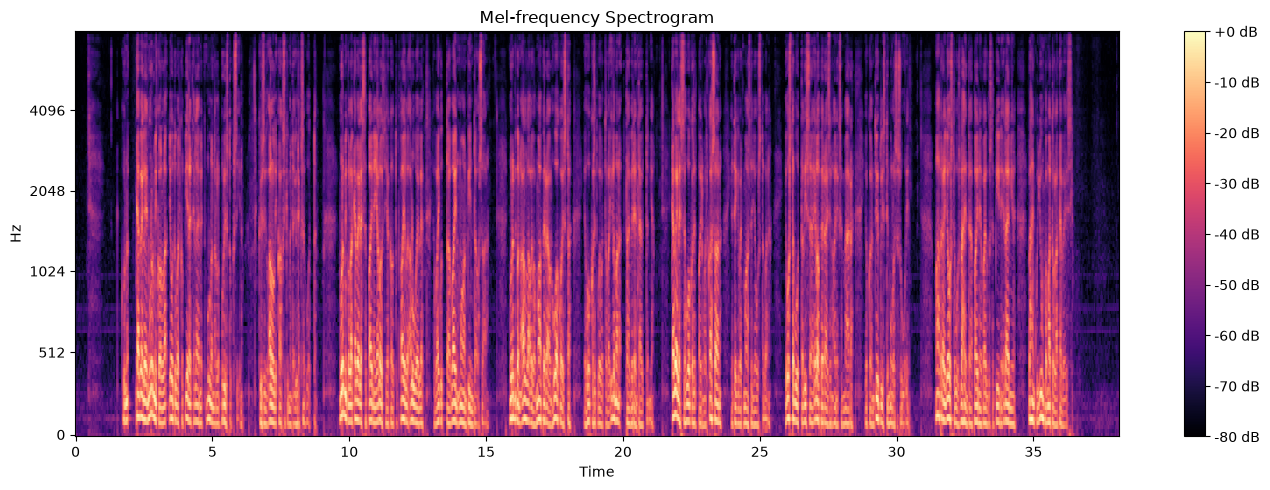

In [3]:
# Plot waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title('Audio Waveform')
plt.tight_layout()
plt.show()

# Create mel spectrogram
plt.figure(figsize=(14, 5))
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-frequency Spectrogram')
plt.tight_layout()
plt.show()

In [4]:
# Valitse laite: NVIDIA-GPU, Apple-GPU tai CPU
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"Using device: {device}")

model_name = "openai/whisper-large-v3"   # vaihtoehtoja: tiny, base, small, medium, large-v3
processor = WhisperProcessor.from_pretrained(model_name)
model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

# Koko äänite kerralla (truncation=False): Whisper käsittelee 30 s pätkissä ja
# ilman tätä yli 30 s pitkä ääni katkeaisi.
inputs = processor(y, sampling_rate=sr, return_tensors="pt",
                   truncation=False, padding="longest",
                   return_attention_mask=True).to(device, model.dtype)

with torch.no_grad():
    generated_ids = model.generate(**inputs, language="fi", task="transcribe",
                                   return_timestamps=True)   # pakollinen yli 30 s äänelle

transcription = processor.batch_decode(
    generated_ids, skip_special_tokens=True,
    clean_up_tokenization_spaces=False)[0].strip()

print("FINNISH TRANSCRIPTION:")
print("=" * 50)
print(transcription)

Using device: mps


Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


FINNISH TRANSCRIPTION:
Kun kävelee nurmikolla, joutuvatko pienet eläimet mullan alla puristuksiin? Kysyy Alli, 29 vuotta. Nurmikolla kävelessä paine jaloista jakautuu laajalle alueelle ja vaikuttaa vain maan pintaosaan. Nurmikon alla oleva maaperä on huokoista ja huokoiset voivat olla ilman tai veden täyttämiä. Kävelessä huokoiset painuvat kasaan ja tekevät maasta joustavan. Joustavuutta lisää eloperäisen aineksen määrä, joka on tyypillisesti muun muassa suuri. Maaperän joustavuus vähentää painevaikutusta pieniä eläimiä vähän kuin jumpa matoilla kävelisi.


In [5]:
# Suomi -> englanti erillisellä käännösmallilla (Whisperin oma "translate" on huono suomelle).
# Käännetään lause kerrallaan, muuten pitkä teksti katkeaa.
mt_name = "Helsinki-NLP/opus-mt-fi-en"
mt_tokenizer = MarianTokenizer.from_pretrained(mt_name)
mt_model = MarianMTModel.from_pretrained(mt_name)

sentences = re.split(r"(?<=[.?!])\s+", transcription)
batch = mt_tokenizer(sentences, return_tensors="pt", padding=True)
with torch.no_grad():
    out = mt_model.generate(**batch)
translation = " ".join(mt_tokenizer.batch_decode(out, skip_special_tokens=True))

print("ENGLISH TRANSLATION:")
print("=" * 50)
print(translation)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
When you walk on the lawn, do small animals get squeezed under the soil? Asks Alli, 29 years old. As you walk on the lawn, the pressure on your feet is spread across a wide area and only affects the surface of the ground. The soil under the lawn is porous and the porous can be filled with air or water. As you walk, the pores sink together and make the ground flexible. Flexibility is increased by the amount of organic matter, which is typically high, among other things. Soil flexibility reduces the pressure effect on small animals a bit like walking on rugs.
